# UCSF Quality Control

After downloading all UCSF patient folders, excluding follow up scans, we are left with 495 patients. All patients have went through `process_chunk.py` and have been preprocessed. Here the UCSF dataset will be compared to the UTSW dataset to see how different the scans are.

Since the crop and preprocessing was determined in the UTSW training set, any findings or differences here should not effect the preprocessing for either the training and test set. The model will be tested on the UCSF dataset even if the crop size is not optimal, which will just be stated as a limitation. 

In [1]:
import numpy as np, pandas as pd
from src.config import LOG, LOG_UCSF, MANIFEST_UCSF, PROCESSED, PROCESSED_UCSF

def latest(path):
    return pd.read_csv(path).drop_duplicates("patient_id", keep="last")

ucsf_all, utsw_all = latest(LOG_UCSF), latest(LOG)
ucsf, utsw = ucsf_all[ucsf_all.status == "ok"], utsw_all[utsw_all.status == "ok"]
manifest = pd.read_csv(MANIFEST_UCSF)

pd.Series({
    "manifest rows": len(manifest),
    "ok in log": len(ucsf),
    "failed in log": int((ucsf_all.status != "ok").sum()),
    "manifest ids == ok ids": set(manifest.patient_id) == set(ucsf.patient_id),
    ".npz files on disk": len(list(PROCESSED_UCSF.glob("*.npz"))),
}, name="UCSF")

manifest rows              495
ok in log                  495
failed in log                0
manifest ids == ok ids    True
.npz files on disk         495
Name: UCSF, dtype: object

### Tumor Statistics Comparison

Here the size of the tumor and its relation to the crop for the UCSF patients were determined. 

In [2]:
def summarize(d):
    longest = d[["bbox_x", "bbox_y", "bbox_z"]].max(axis=1)
    return {
        "patients": len(d),
        "tumor inside brain, min": d.tumor_in_brain.min(),
        "longest tumor side, median (voxels)": longest.median(),
        "longest tumor side, 25th pct": longest.quantile(.25),
        "longest tumor side, 75th pct": longest.quantile(.75),
        "longest tumor side, max": longest.max(),
        "% with a side > 128": 100 * (longest > 128).mean(),
        "% keeping < 99% of tumor in crop": 100 * (d.tumor_in_crop < 0.99).mean(),
        "min tumor share kept in crop": d.tumor_in_crop.min(),
        "% largest piece < 90% of tumor": 100 * (d.main_fraction < 0.9).mean(),
        "tumor voxels in crop, median": d.mask_voxels.median(),
        "tumor voxels in crop, min": d.mask_voxels.min(),
    }

pd.DataFrame({"UTSW": summarize(utsw), "UCSF": summarize(ucsf)}).round(3)

,UTSW,UCSF
patients,617.000,495.000
"tumor inside brain, min",0.989,0.985
"longest tumor side, median (voxels)",74.000,78.000
"longest tumor side, 25th pct",56.000,61.000
"longest tumor side, 75th pct",92.000,95.000
"longest tumor side, max",148.000,166.000
% with a side > 128,0.486,1.010
% keeping < 99% of tumor in crop,0.810,1.212
min tumor share kept in crop,0.956,0.884
% largest piece < 90% of tumor,7.131,5.657


### Findings 
- UCSF tumors are larger than UTSW tumors. The median tumor voxels in the crop is 81,746 vs. 70,407. The minimum tumor voxels in the crop for UCSF is 971, which is why no patient was excluded. 
- ~1% (5 patients) of UCSF tumors excceds the crop window on at least one axis. ~1.2% (6 patients) of UCSF patients keep less than 99% of their tumor in the crop. With the worst being 88.4% kept in the crop, whereas UTSW had 95.6% as the worst percentage kept in the crop. 

**Limitation:** This difference in size could be caused by the segmentation method used for the datasets. 

### Intensity Distribution

Means and standard deviations should match and be close due to the z-score normalization. The check below sees how close the datasets match on 60 patients (to save on compute). The 5th, 50th, and 95th nonzero voxels for each contrasts are also calculated.  

In [3]:
rng = np.random.default_rng(42)

def intensity_stats(folder, d, n=60):
    rows = []
    for pid in rng.choice(sorted(d.patient_id), n, replace=False):
        with np.load(folder / f"{pid}.npz") as f:
            img = f["image"].astype(np.float32)
        for c, name in enumerate(["T1", "T1c", "T2", "FLAIR"]):
            nz = img[c] != 0
            p5, p50, p95 = np.percentile(img[c][nz], [5, 50, 95])
            rows.append(dict(channel=name, share_nonzero=nz.mean(), p5=p5, p50=p50, p95=p95))
    return pd.DataFrame(rows).groupby("channel").median()

order = ["T1", "T1c", "T2", "FLAIR"]
pd.concat({"UTSW": intensity_stats(PROCESSED, utsw).loc[order],
           "UCSF": intensity_stats(PROCESSED_UCSF, ucsf).loc[order]}, axis=1).round(2)

UTSW                            UCSF                  
        share_nonzero    p5   p50   p95 share_nonzero    p5   p50   p95
channel                                                                
T1               0.45 -1.88  0.23  1.31          0.46 -1.77  0.15  1.42
T1c              0.45 -1.68  0.14  1.27          0.46 -1.42  0.04  1.22
T2               0.45 -0.99 -0.27  2.25          0.46 -0.91 -0.29  2.25
FLAIR            0.45 -1.74  0.06  1.80          0.46 -1.76 -0.05  1.61

Values in the table above are fairly close and do not deviate significantly. 

### Visualize
Do the crops look the same way? 

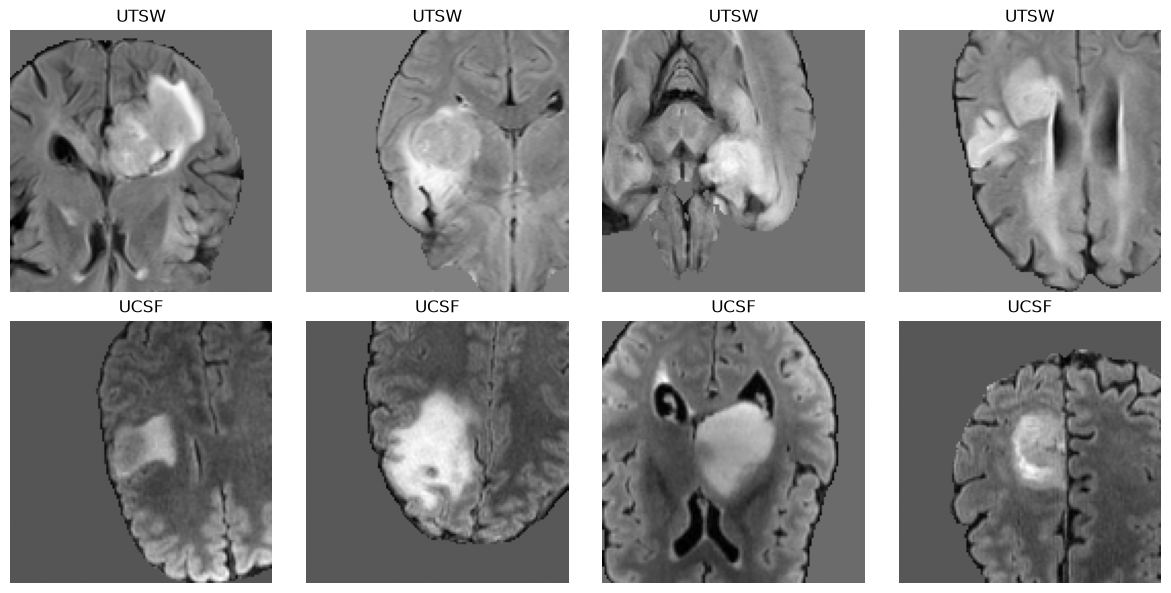

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for row, (name, d, folder) in enumerate([("UTSW", utsw, PROCESSED), ("UCSF", ucsf, PROCESSED_UCSF)]):
    for col, pid in enumerate(rng.choice(sorted(d.patient_id), 4, replace=False)):
        with np.load(folder / f"{pid}.npz") as f:
            flair = f["image"][3, :, :, 64].astype(np.float32)
        ax[row, col].imshow(np.rot90(flair), cmap="gray")
        ax[row, col].set_title(name)
        ax[row, col].axis("off")
plt.tight_layout(); plt.show()

All scans and contrasts are orientated the same way as expected (both should be LPS). 